# Indian city air quality: coverage, seasonal patterns and high-AQI days

The analysis examines daily city records from the supplied 2015–2020 archive. It treats monitoring coverage as part of the question: a city with many missing days cannot be compared as confidently as one with a near-complete series.

## Data and scope

Source: [air-quality-data-in-india](https://www.kaggle.com/datasets/rohanrao/air-quality-data-in-india). This report uses the uploaded snapshot, not live data.

`city_day.csv` contains city-date observations. `City` and `Date` are the key. `AQI` is the supplied air quality index and `AQI_Bucket` its category. `PM2.5`, `PM10`, `NO`, `NO2`, `NOx`, `NH3`, `CO`, `SO2`, `O3`, `Benzene`, `Toluene` and `Xylene` are reported pollutant concentrations. Concentrations and AQI are different quantities; this project does not add pollutant columns together or recalculate the index.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

%matplotlib inline
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

def data_path(filename):
    # Works after extracting this ZIP, or after attaching its data on Kaggle.
    for folder in (Path("data"), Path(".")):
        candidate = folder / filename
        if candidate.is_file():
            return candidate
    kaggle = Path("/kaggle/input")
    matches = sorted(kaggle.rglob(filename)) if kaggle.exists() else []
    if len(matches) == 1:
        return matches[0]
    raise FileNotFoundError(f"Place {filename} in data/, or attach its dataset on Kaggle. Found {len(matches)} Kaggle matches.")

In [2]:
raw = pd.read_csv(data_path("city_day.csv"))
print(f"Raw data: {len(raw):,} rows, {raw.shape[1]} columns")
assert len(raw)>=150 and raw.shape[1]>=3
display(raw.head()); display(raw.isna().sum().to_frame("missing"))

Raw data: 29,531 rows, 16 columns


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.920,18.220,17.150,NaN,0.920,27.640,133.360,0.000,0.020,0.000,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.970,15.690,16.460,NaN,0.970,24.550,34.060,3.680,5.500,3.770,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.400,19.300,29.700,NaN,17.400,29.070,30.700,6.800,16.400,2.250,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.700,18.480,17.970,NaN,1.700,18.590,36.080,4.430,10.140,1.000,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.100,21.420,37.760,NaN,22.100,39.330,39.310,7.010,18.890,2.780,NaN,NaN


,missing
City,0
Date,0
PM2.5,4598
PM10,11140
NO,3582
NO2,3585
NOx,4185
NH3,10328
CO,2059
SO2,3854


Negative numeric readings made missing: 0; city-date rows: 29,531
Largest reported AQI readings retained for review; no unverified upper cap is imposed:


,rows,aqi_days,first,last,span_days,coverage_pct
City,,,,,,
Mumbai,2009,775,2015-01-01,2020-07-01,2009,38.576
Jorapokhar,1169,771,2017-04-20,2020-07-01,1169,65.954
Shillong,310,205,2019-08-27,2020-07-01,310,66.129
Ahmedabad,2009,1334,2015-01-01,2020-07-01,2009,66.401
Talcher,925,698,2017-12-20,2020-07-01,925,75.459
Brajrajnagar,938,713,2017-12-07,2020-07-01,938,76.013
Patna,1858,1459,2015-06-01,2020-07-01,1858,78.525
Visakhapatnam,1462,1171,2016-07-01,2020-07-01,1462,80.096
Gurugram,1679,1453,2015-11-27,2020-07-01,1679,86.540


,count,mean,std,min,25%,50%,75%,max
AQI,"24,850.000",166.464,140.697,13.000,81.000,118.000,208.000,"2,049.000"
PM2.5,"24,933.000",67.451,64.661,0.040,28.820,48.570,80.590,949.990
PM10,"18,391.000",118.127,90.605,0.010,56.255,95.680,149.745,"1,000.000"
NO2,"25,946.000",28.561,24.475,0.010,11.750,21.690,37.620,362.210
CO,"27,472.000",2.249,6.963,0.000,0.510,0.890,1.450,175.810
O3,"25,509.000",34.491,21.695,0.010,18.860,30.840,45.570,257.730


,City,Date,AQI
1145,Ahmedabad,2018-02-19,"2,049.000"
1136,Ahmedabad,2018-02-10,"1,917.000"
560,Ahmedabad,2016-07-14,"1,842.000"
1048,Ahmedabad,2017-11-14,"1,747.000"
1463,Ahmedabad,2019-01-03,"1,719.000"


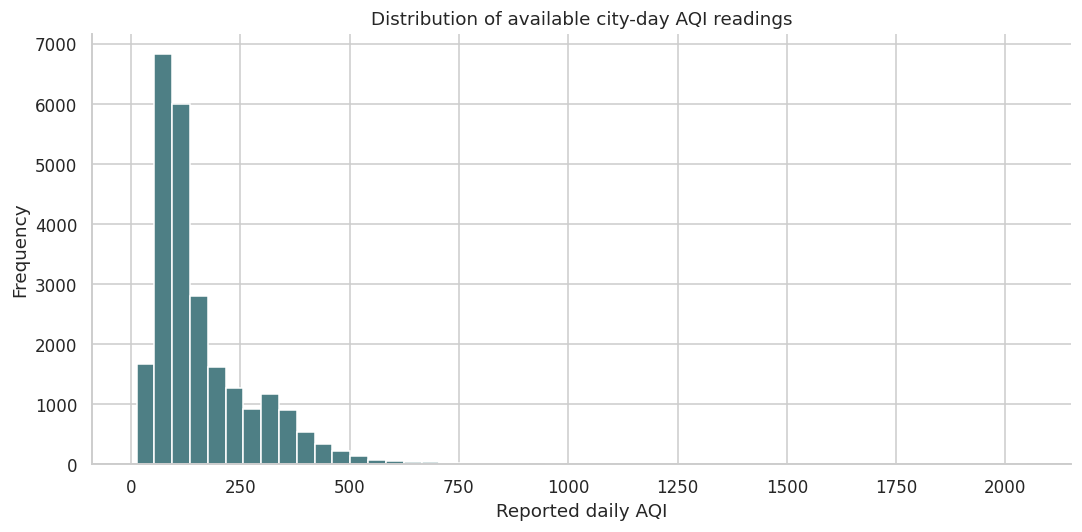

In [3]:
df = raw.drop_duplicates().copy()
df["Date"] = pd.to_datetime(df.Date,errors="coerce")
numeric = df.select_dtypes(include="number").columns
negatives = (df[numeric]<0).sum().sum()
df[numeric] = df[numeric].mask(df[numeric]<0)
df = df.dropna(subset=["City","Date"])
assert not df.duplicated(["City","Date"]).any()
df["year"] = df.Date.dt.year
df["month"] = df.Date.dt.month
coverage = df.groupby("City").agg(rows=("Date","size"),aqi_days=("AQI","count"),first=("Date","min"),last=("Date","max"))
coverage["span_days"] = (coverage["last"]-coverage["first"]).dt.days+1
coverage["coverage_pct"] = coverage.aqi_days/coverage.span_days*100
print(f"Negative numeric readings made missing: {negatives}; city-date rows: {len(df):,}")
display(coverage.sort_values("coverage_pct"))
display(df[["AQI","PM2.5","PM10","NO2","CO","O3"]].describe().T)
print("Largest reported AQI readings retained for review; no unverified upper cap is imposed:")
display(df.nlargest(5,"AQI")[["City","Date","AQI"]])
df.AQI.plot.hist(bins=50,color="#4e7f85")
plt.xlabel("Reported daily AQI"); plt.title("Distribution of available city-day AQI readings")
plt.tight_layout(); plt.show()

## 1. Which cities have the highest typical recorded AQI?

Only cities with at least 365 nonmissing AQI readings are ranked. The table includes the count and interquartile range. This minimum-count rule improves stability, but it does not make the monitoring periods identical.

,count,median,mean,q25,q75
City,,,,,
Ahmedabad,1334,384.500,452.123,231.000,542.750
Delhi,1999,257.000,259.488,161.500,345.500
Patna,1459,215.000,240.782,131.000,343.000
Gurugram,1453,208.000,225.124,123.000,321.000
Lucknow,1893,198.000,217.973,111.000,322.000
Jorapokhar,771,133.000,159.252,106.000,186.000
Talcher,698,128.500,172.887,102.000,237.500
Jaipur,1094,122.000,133.679,96.000,159.000
Brajrajnagar,713,122.000,150.281,103.000,188.000


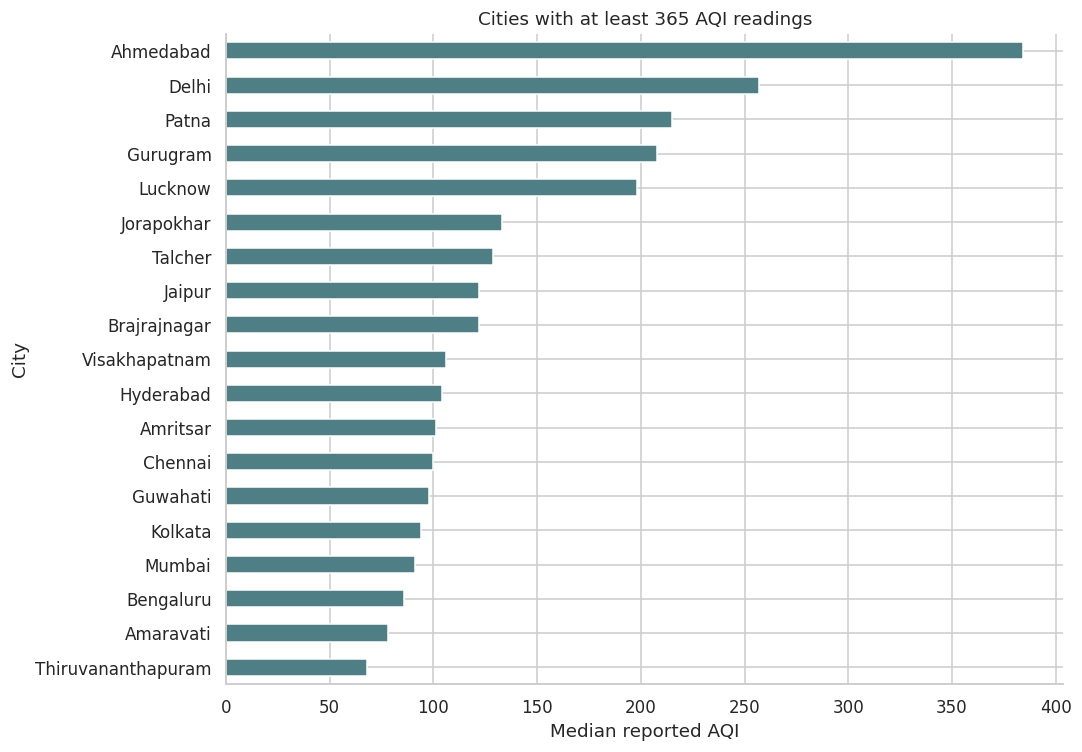

In [4]:
city = df.groupby("City").AQI.agg(count="count",median="median",mean="mean",q25=lambda x:x.quantile(.25),q75=lambda x:x.quantile(.75))
ranked = city[city["count"]>=365].sort_values("median",ascending=False)
display(ranked)
ranked["median"].sort_values().plot.barh(color="#4e7f85",figsize=(10,7))
plt.xlabel("Median reported AQI"); plt.title("Cities with at least 365 AQI readings")
plt.tight_layout(); plt.show()

**Answer.** Ahmedabad has the highest median recorded AQI among eligible cities (384.5), based on 1,334 readings. These cities have different date coverage, so this is not a controlled city league table.

## 2. How does Delhi AQI vary through the year?

Delhi is used as a single-city seasonal case study. Monthly medians pool available years, and counts are shown alongside them. `boxplot()` shows the spread and outliers rather than only twelve averages.

,count,median,mean
month,,,
1,186,358.000,360.387
2,170,312.500,298.829
3,186,217.000,222.624
4,180,252.500,248.444
5,186,254.500,258.694
6,179,185.000,199.419
7,155,130.000,137.574
8,147,111.000,134.442
9,150,136.500,157.427


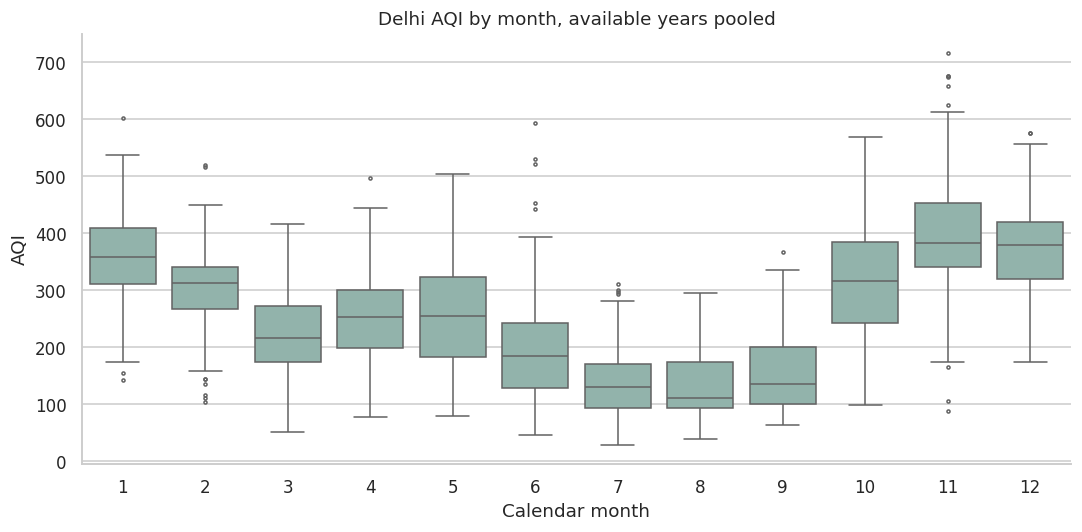

In [5]:
delhi = df[df.City.eq("Delhi")].dropna(subset=["AQI"]).copy()
monthly = delhi.groupby("month").AQI.agg(["count","median","mean"])
display(monthly)
sns.boxplot(data=delhi,x="month",y="AQI",color="#8cb9ae",fliersize=2)
plt.xlabel("Calendar month"); plt.title("Delhi AQI by month, available years pooled")
plt.tight_layout(); plt.show()

**Answer.** Delhi’s highest monthly median occurs in month 11 (383.5), and its lowest in month 8 (111.0). This pattern is descriptive; weather, emissions and monitoring changes are not separated here.

## 3. How frequently is AQI above 200 in each eligible city?

The threshold is explicitly defined as AQI greater than 200. The denominator is nonmissing AQI days, not all rows. A missing reading is never counted as a low-AQI day.

,count,sum,share_pct
City,,,
Ahmedabad,1334,1092,81.859
Delhi,1999,1301,65.083
Patna,1459,781,53.530
Gurugram,1453,753,51.824
Lucknow,1893,935,49.392
Talcher,698,205,29.370
Guwahati,495,133,26.869
Kolkata,754,198,26.260
Jorapokhar,771,173,22.438


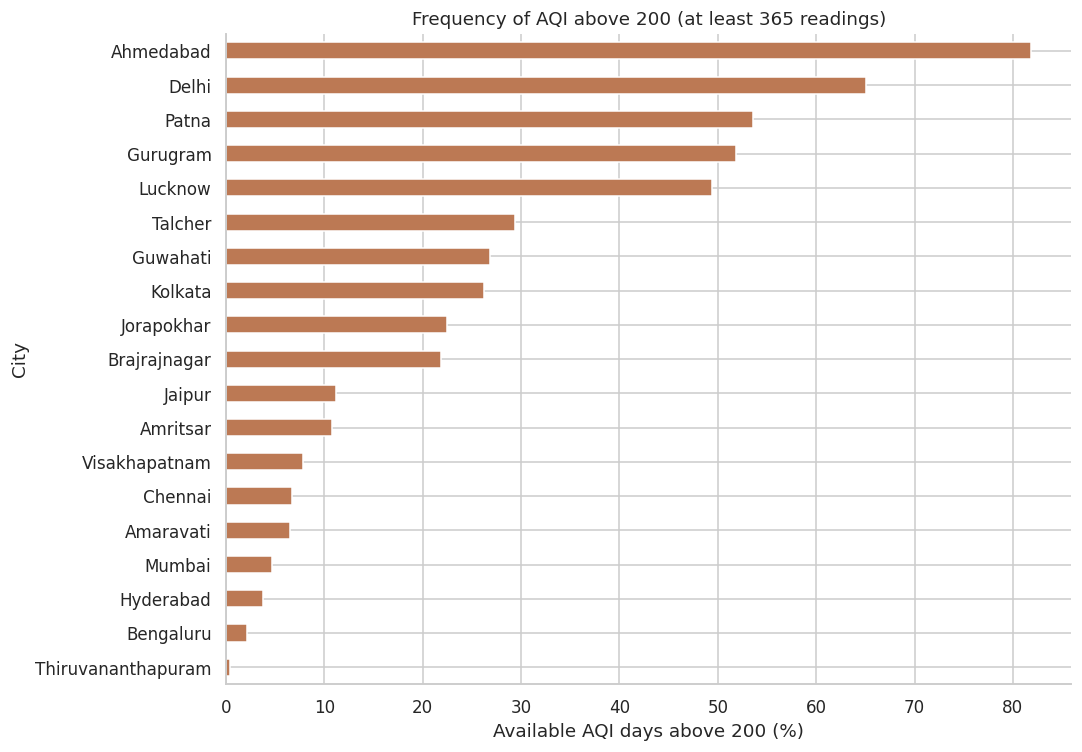

In [6]:
observed = df.dropna(subset=["AQI"]).copy()
observed["above_200"] = observed.AQI.gt(200)
high = observed.groupby("City").above_200.agg(["count","sum","mean"])
high["share_pct"] = high["mean"]*100
high = high[high["count"]>=365].sort_values("share_pct",ascending=False)
display(high[["count","sum","share_pct"]])
high.share_pct.sort_values().plot.barh(color="#bc7954",figsize=(10,7))
plt.xlabel("Available AQI days above 200 (%)"); plt.title("Frequency of AQI above 200 (at least 365 readings)")
plt.tight_layout(); plt.show()

**Answer.** Ahmedabad has the highest observed share: 81.9% (1,092 of 1,334 AQI days). The proportion can still be biased if missing readings are concentrated in particular seasons.

## 4. Which reported pollutants are most associated with AQI in Delhi?

`corr(method="spearman")` measures rank association. Pairwise observation counts are reported because pollutant coverage differs. AQI is derived from pollutant information, so an association is partly built into its construction and is not proof of a causal contribution.

,spearman_rho,paired_days
PM2.5,0.923,1998
PM10,0.882,1930
NO2,0.696,1998
CO,0.583,1999
SO2,0.478,1897
O3,0.267,1923


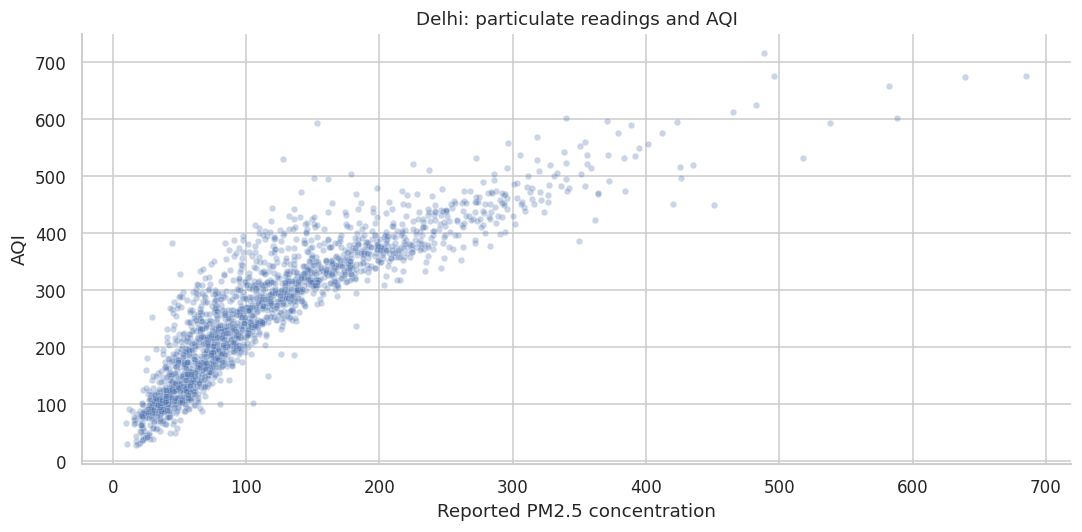

In [7]:
pollutants = ["PM2.5","PM10","NO2","CO","SO2","O3"]
associations = pd.DataFrame({"spearman_rho":delhi[pollutants].corrwith(delhi.AQI,method="spearman"),"paired_days":[delhi[["AQI",p]].dropna().shape[0] for p in pollutants]}).sort_values("spearman_rho",ascending=False)
display(associations)
sns.scatterplot(data=delhi,x="PM2.5",y="AQI",alpha=.3,s=18)
plt.xlabel("Reported PM2.5 concentration"); plt.title("Delhi: particulate readings and AQI")
plt.tight_layout(); plt.show()

**Answer.** PM2.5 has the highest rank correlation with Delhi AQI among the six fields examined (0.923), using 1,998 paired days. These coefficients cannot be used to divide AQI into causal pollutant shares.

## 5. How do complete calendar-year summaries compare?

This comparison omits 2020 because the archive ends during that year. Delhi, Mumbai and Bengaluru are shown where a city-year has at least 300 AQI readings. `where()` suppresses estimates that fail that coverage rule.

count  median  eligible_median
year City                                     
2015 Bengaluru    286  99.500              NaN
     Delhi        365 303.000          303.000
     Mumbai         0     NaN              NaN
2016 Bengaluru    351 102.000          102.000
     Delhi        365 293.000          293.000
     Mumbai         0     NaN              NaN
2017 Bengaluru    364  78.500           78.500
     Delhi        356 280.000          280.000
     Mumbai         0     NaN              NaN
2018 Bengaluru    361  81.000           81.000
     Delhi        365 243.000          243.000
     Mumbai       227  90.000              NaN
2019 Bengaluru    365  89.000           89.000
     Delhi        365 209.000          209.000
     Mumbai       365  93.000           93.000

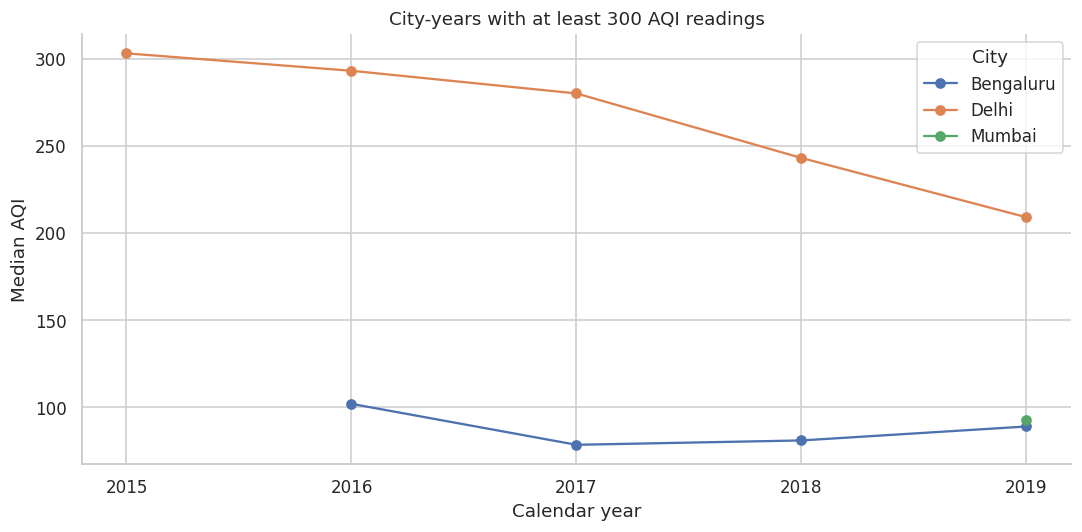

In [8]:
selected = df[df.City.isin(["Delhi","Mumbai","Bengaluru"]) & df.year.lt(2020)]
annual = selected.groupby(["year","City"]).AQI.agg(["count","median"])
annual["eligible_median"] = annual["median"].where(annual["count"]>=300)
display(annual)
annual.eligible_median.unstack().plot(marker="o")
plt.xticks(sorted(selected.year.unique()))
plt.xlabel("Calendar year"); plt.ylabel("Median AQI"); plt.title("City-years with at least 300 AQI readings")
plt.tight_layout(); plt.show()

**Answer.** 10 of 15 candidate city-years meet the 300-day rule. Gaps in the plot are deliberately retained. Even these annual medians can be affected by the seasonal distribution of the missing days.

## Conclusion

Delhi’s pooled monthly median AQI is highest in November at 383.5 and lowest in August at 111.0. Only 10 of the 15 selected city-years meet the 300-reading rule, which limits the annual comparison.

Recorded pollution levels differ substantially between cities and across months. The coverage tables are essential for interpreting those differences. Delhi’s monthly distribution provides a clearer seasonal comparison than pooling all cities and years into one average.
